# Лабораторна робота 4
## Візуалізація даних: графіки та гістограми у Matplotlib і Seaborn

**Датасет:** очищений датасет туристичних маршрутів із ЛР 3 (`data/processed/processed_routes.csv`; сирі дані — `data/raw/routes_dataset.csv`).

**Мета:** навчитися візуально досліджувати дані — будувати й інтерпретувати гістограми, box plot, діаграми розсіювання, теплові карти, лінійні графіки, знаходити закономірності, взаємозв'язки та аномалії.

> Датасет згенеровано автоматично (ЛР 3), тому деякі залежності в ньому свідомо слабкі або відсутні. У висновках це зазначено окремо: відсутність зв'язку — теж результат аналізу.

## 1. Підготовка середовища та завантаження даних

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")
NO_GRID = {"axes.grid": False}
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 11, "savefig.bbox": "tight"})

# --- Google Colab: завантаження файлу вручну (в Jupyter блок пропускається) ---
CANDIDATES = [Path("../data/processed/processed_routes.csv"), Path("data/processed/processed_routes.csv"),
              Path("processed_routes.csv")]
DATA_FILE = next((p for p in CANDIDATES if p.exists()), Path("processed_routes.csv"))
try:
    from google.colab import files
    if not DATA_FILE.exists():
        print("Оберіть файл processed_routes.csv...")
        files.upload()
except ImportError:
    pass

# Папка для графіків: figures/ у корені проєкту (або поруч із ноутбуком у Colab)
FIG_DIR = Path("../figures") if Path("../data").exists() else Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(name):
    """Зберігає поточний графік у PNG."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150)

df = pd.read_csv(DATA_FILE, parse_dates=["date_added"])
print("Датасет зчитано:", DATA_FILE)

Датасет зчитано: ../data/processed/processed_routes.csv


## 2. Первинне ознайомлення з даними

In [2]:
df.head()

,route_id,type,name,country,start_city,length_km,description,ratings,difficulty,elevation_gain_m,...,stops_count,date_added,price_eur,avg_rating,ratings_count,duration_hours,price_per_km,length_class,year_added,popularity_score
0,229,BusTour,Екскурсійний тур Балтики (Пассау),Австрія,Пассау,282.6,Маршрут проходить через національний парк.,8 8 8,NaN,NaN,...,3.0,2025-08-17,111.95,8.00,3,7.82,0.40,довга,2025.0,54
1,10,CyclingRoute,Веломаршрут Фйордів (Шамоні),Франція,Шамоні,191.4,Мальовничий маршрут з чудовими краєвидами.,5 6 7 8 9 5 7,NaN,NaN,...,NaN,2023-03-19,44.56,6.71,7,19.14,0.23,довга,2023.0,89
2,58,CyclingRoute,Веломаршрут Доломітів (Відень),Австрія,Відень,293.4,Мальовничий маршрут з чудовими краєвидами.,NaN,NaN,NaN,...,NaN,2025-06-24,248.80,NaN,0,29.34,0.85,довга,2025.0,83
3,61,BusTour,Екскурсійний тур Карпат (Одеса),Україна,Одеса,423.3,Є кемпінги та місця для відпочинку по дорозі.,9 9 9 7,NaN,NaN,...,10.0,2024-09-09,347.18,8.50,4,13.08,0.82,дуже довга,2024.0,72
4,26,HikingRoute,Стежка Карпат (Пассау),Австрія,Пассау,6.3,Опис відсутній,8 7 7 8 6 6 8,складний,2252.0,...,NaN,2025-11-21,303.91,7.14,7,5.33,48.24,коротка,2025.0,72


In [3]:
df.tail()

,route_id,type,name,country,start_city,length_km,description,ratings,difficulty,elevation_gain_m,...,stops_count,date_added,price_eur,avg_rating,ratings_count,duration_hours,price_per_km,length_class,year_added,popularity_score
283,21,BusTour,Автобусом через Старого міста (Інтерлакен),Швейцарія,Інтерлакен,790.8,Маршрут проходить через національний парк.,8 9 10 7 9 10,NaN,NaN,...,10.0,2024-04-29,454.99,8.83,6,22.27,0.58,дуже довга,2024.0,75
284,72,CyclingRoute,Веломаршрут Фйордів (Ставангер),Норвегія,Ставангер,140.1,Підходить для підготовлених туристів.,10 9 10 10,NaN,NaN,...,NaN,2025-08-30,282.42,9.75,4,14.01,2.02,довга,2025.0,72
285,107,CyclingRoute,Трейл Татр (Одеса),Україна,Одеса,160.7,Популярний маршрут у літній сезон.,8 5 5,NaN,NaN,...,NaN,2023-03-03,460.42,6.00,3,10.71,2.87,довга,2023.0,97
286,271,HikingRoute,Піший похід Альп (Братислава),Словаччина,Братислава,19.0,Зручний варіант для вихідних.,6 9,складний,1360.0,...,NaN,2024-09-29,534.86,7.50,2,7.02,28.15,коротка,2024.0,58
287,103,HikingRoute,Трек через Озерного краю (Берген),Норвегія,Берген,50.1,Маршрут проходить через національний парк.,10 10 10 7,легкий,517.0,...,NaN,2024-10-09,145.81,9.25,4,13.39,2.91,середня,2024.0,79


In [4]:
print("Рядків:", df.shape[0], "| Стовпців:", df.shape[1])
df.dtypes

Рядків: 288 | Стовпців: 21


route_id                     int64
type                           str
name                           str
country                        str
start_city                     str
length_km                  float64
description                    str
ratings                        str
difficulty                     str
elevation_gain_m           float64
bike_type                      str
stops_count                float64
date_added          datetime64[us]
price_eur                  float64
avg_rating                 float64
ratings_count                int64
duration_hours             float64
price_per_km               float64
length_class                   str
year_added                 float64
popularity_score             int64
dtype: object

In [5]:
numeric_cols = ["length_km", "price_eur", "avg_rating", "duration_hours", "price_per_km",
                "elevation_gain_m", "stops_count", "ratings_count", "popularity_score"]
df[numeric_cols].describe().round(2)

,length_km,price_eur,avg_rating,duration_hours,price_per_km,elevation_gain_m,stops_count,ratings_count,popularity_score
count,288.00,288.00,276.00,288.00,288.00,109.00,52.00,288.00,288.00
mean,143.42,258.29,7.92,11.02,6.25,1436.45,7.35,4.29,74.92
std,194.44,188.19,0.98,7.13,10.33,794.20,3.81,1.88,13.90
min,2.00,1.90,5.50,0.40,0.07,135.00,2.00,0.00,50.00
25%,16.38,79.66,7.24,4.84,1.07,748.00,4.00,3.00,64.00
50%,56.45,264.27,8.00,10.55,2.72,1450.00,7.00,4.00,75.00
75%,200.65,415.26,8.67,16.56,7.26,1980.00,10.25,6.00,86.25
max,866.70,599.32,10.00,34.74,87.42,2978.00,14.00,7.00,100.00


In [6]:
print("Дублікатів:", df.duplicated().sum(), "| Унікальних route_id:", df["route_id"].is_unique)
pd.DataFrame({"пропусків": df.isnull().sum(), "%": (df.isnull().mean() * 100).round(1)})

Дублікатів: 0 | Унікальних route_id: True


,пропусків,%
route_id,0,0.0
type,0,0.0
name,0,0.0
country,0,0.0
start_city,0,0.0
length_km,0,0.0
description,0,0.0
ratings,12,4.2
difficulty,179,62.2
elevation_gain_m,179,62.2


**Попереднє очищення.** Дані вже очищено в ЛР 3, тож дублікатів немає. Залишені пропуски мають зрозумілі причини:

- `difficulty`, `elevation_gain_m`, `bike_type`, `stops_count` — поля, що існують лише для одного типу маршруту (структурні пропуски);
- `avg_rating` — маршрути без жодного валідного відгуку;
- `date_added` — кілька некоректних дат, які не вдалося розпізнати.

Заповнювати їх не потрібно: кожен графік сам відкидає `NaN` у використаних стовпцях. Додамо зручні для підписів українські назви типів і фіксовану палітру, щоб один тип маршруту мав той самий колір на всіх графіках.

In [7]:
TYPE_UA = {"Route": "Прогулянка", "HikingRoute": "Пішохідний", "CyclingRoute": "Велосипедний", "BusTour": "Автобусний тур"}
TYPE_ORDER = ["Прогулянка", "Пішохідний", "Велосипедний", "Автобусний тур"]
PALETTE = dict(zip(TYPE_ORDER, sns.color_palette("Set2", 4)))

df["type_ua"] = pd.Categorical(df["type"].map(TYPE_UA), categories=TYPE_ORDER, ordered=True)
df["length_class"] = pd.Categorical(df["length_class"], categories=["коротка", "середня", "довга", "дуже довга"], ordered=True)
df["type_ua"].value_counts()

type_ua
Пішохідний        109
Велосипедний       73
Прогулянка         54
Автобусний тур     52
Name: count, dtype: int64

## 3. Розподіл числових змінних

### 3.1. Гістограми з KDE-кривою

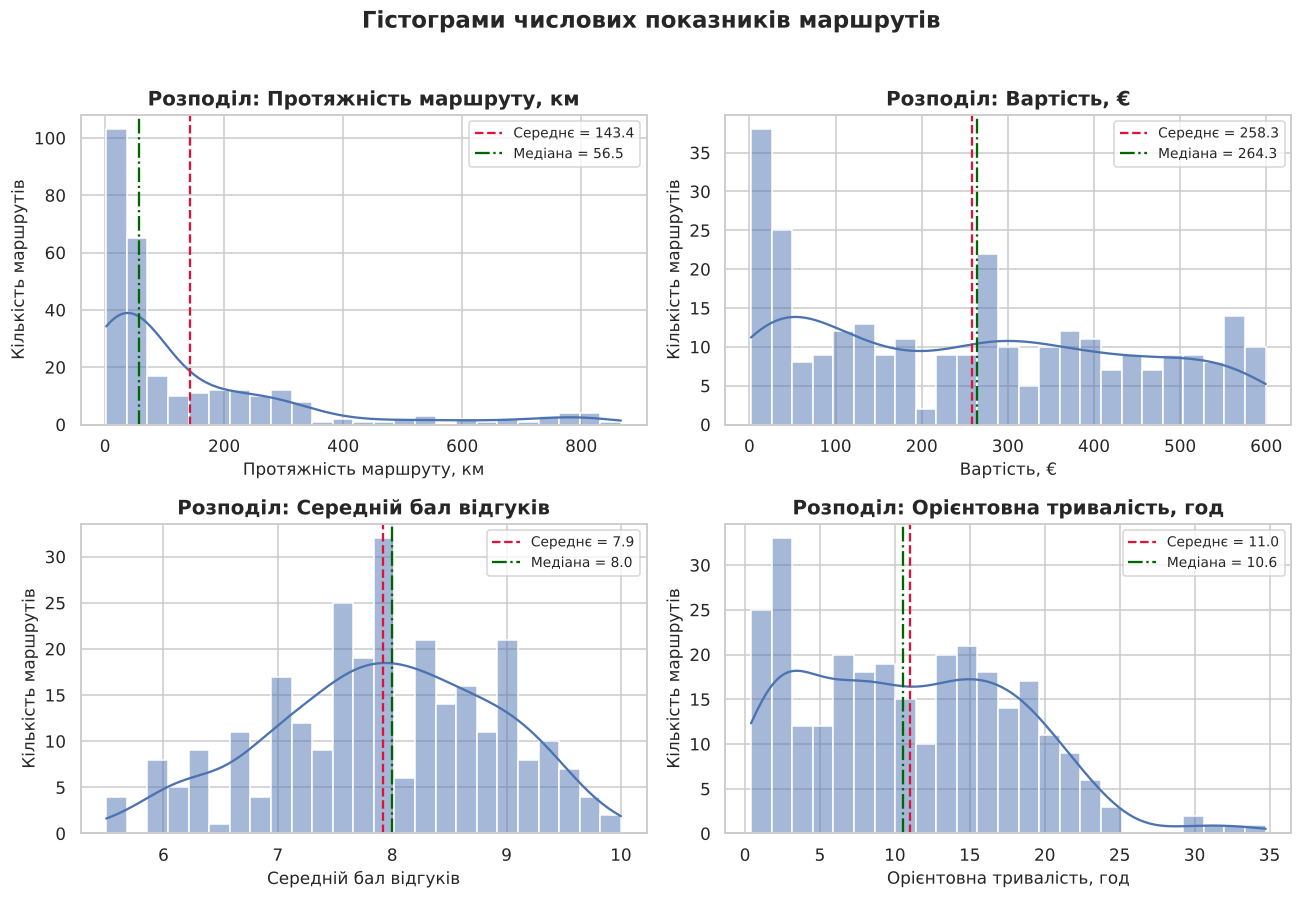

Асиметрія (skewness):
length_km         2.07
price_eur         0.22
avg_rating       -0.25
duration_hours    0.41


In [8]:
variables = {"length_km": "Протяжність маршруту, км", "price_eur": "Вартість, €",
             "avg_rating": "Середній бал відгуків", "duration_hours": "Орієнтовна тривалість, год"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, label) in zip(axes.ravel(), variables.items()):
    sns.histplot(df[col], bins=25, kde=True, color="#4C72B0", ax=ax)
    ax.axvline(df[col].mean(), color="crimson", ls="--", label=f"Середнє = {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="darkgreen", ls="-.", label=f"Медіана = {df[col].median():.1f}")
    ax.set(title=f"Розподіл: {label}", xlabel=label, ylabel="Кількість маршрутів")
    ax.legend(fontsize=9)
fig.suptitle("Гістограми числових показників маршрутів", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
save("01_histograms")
plt.show()

print("Асиметрія (skewness):")
print(df[list(variables)].skew().round(2).to_string())

**Інтерпретація.**

- **Протяжність** — різко асиметричний розподіл із довгим правим «хвостом» (skewness ≈ 2,07): більшість маршрутів коротші за 100 км, медіана 56,5 км набагато менша за середнє 143,4 км. Хвіст створюють автобусні тури до 867 км. Для такого показника коректніше спиратися на медіану, а не на середнє.
- **Вартість** майже рівномірно розподілена між 0 і 600 € (середнє 258 ≈ медіана 264, skewness 0,22). Окремий пік біля нуля — це дешеві прогулянки (до 40 €).
- **Середній бал** має майже симетричний дзвіноподібний розподіл із невеликим зсувом ліворуч (skewness −0,25), центр близько 8; значення лежать у межах 5,5–10, оцінки концентруються в діапазоні 7–9.
- **Тривалість** має пік біля 1–3 год (прогулянки), широке «плато» 5–20 год і тонкий хвіст до 35 год.

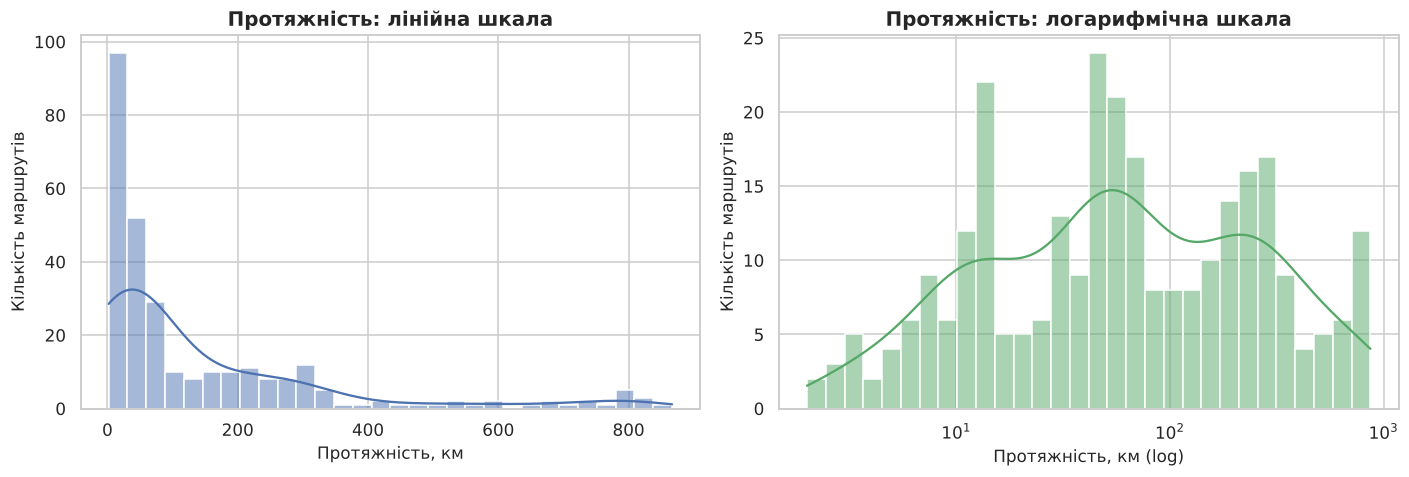

In [9]:
# Протяжність сильно скошена праворуч -> логарифмічна шкала дає змогу побачити структуру розподілу
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["length_km"], bins=30, kde=True, color="#4C72B0", ax=axes[0])
axes[0].set(title="Протяжність: лінійна шкала", xlabel="Протяжність, км", ylabel="Кількість маршрутів")
sns.histplot(df["length_km"], bins=30, kde=True, log_scale=True, color="#55A868", ax=axes[1])
axes[1].set(title="Протяжність: логарифмічна шкала", xlabel="Протяжність, км (log)", ylabel="Кількість маршрутів")
plt.tight_layout()
save("02_length_linear_vs_log")
plt.show()

### 3.2. KDE: порівняння розподілів за типами маршруту

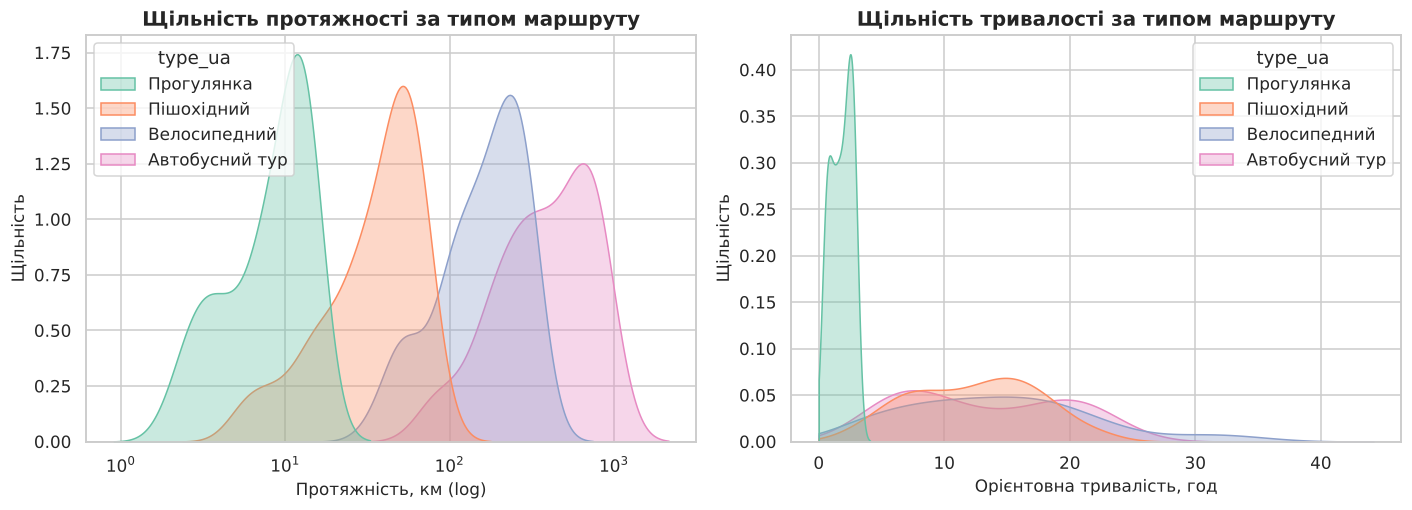

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.kdeplot(data=df, x="length_km", hue="type_ua", hue_order=TYPE_ORDER, palette=PALETTE,
            log_scale=True, fill=True, alpha=0.35, common_norm=False, ax=axes[0])
axes[0].set(title="Щільність протяжності за типом маршруту", xlabel="Протяжність, км (log)", ylabel="Щільність")
sns.kdeplot(data=df, x="duration_hours", hue="type_ua", hue_order=TYPE_ORDER, palette=PALETTE,
            fill=True, alpha=0.35, common_norm=False, clip=(0, None), ax=axes[1])
axes[1].set(title="Щільність тривалості за типом маршруту", xlabel="Орієнтовна тривалість, год", ylabel="Щільність")
plt.tight_layout()
save("03_kde_by_type")
plt.show()

**Інтерпретація.** Типи маршрутів майже не перетинаються за протяжністю: медіани становлять ≈ 9 км (прогулянки), 42 км (пішохідні), 181 км (велосипедні) та 409 км (автобусні тури), тому на логарифмічній шкалі видно чотири окремі «горби». За тривалістю картина інша: прогулянки (медіана ≈ 1,9 год) чітко відокремлені, а пішохідні, велосипедні й автобусні маршрути з медіанами 12,4–14,0 год значно перекриваються — повільніші види транспорту компенсуються меншою протяжністю.

## 4. Box Plot і пошук аномалій

### 4.1. Розмах, медіана, квартилі

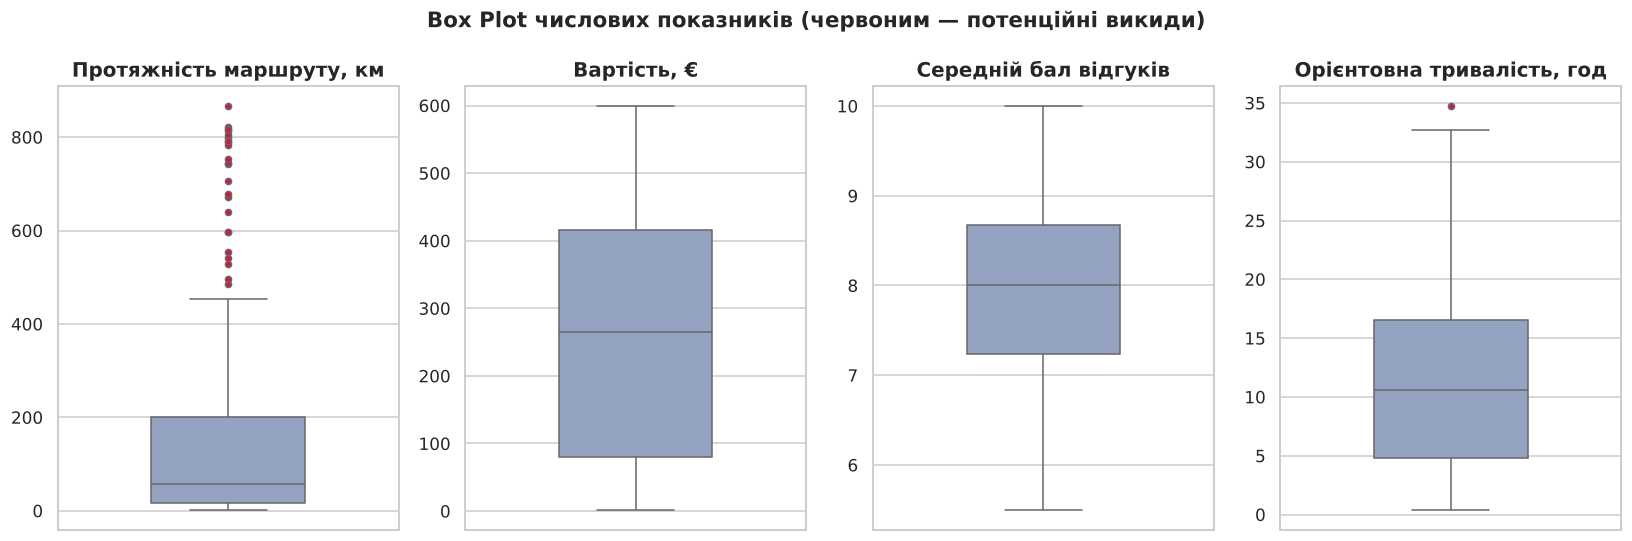

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 5))
for ax, (col, label) in zip(axes, variables.items()):
    sns.boxplot(y=df[col], color="#8DA0CB", width=0.45, flierprops={"marker": "o", "markerfacecolor": "crimson", "markersize": 4}, ax=ax)
    ax.set(title=label, ylabel="", xlabel="")
fig.suptitle("Box Plot числових показників (червоним — потенційні викиди)", fontsize=14, fontweight="bold")
plt.tight_layout()
save("04_boxplots_numeric")
plt.show()

In [12]:
def iqr_summary(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series({"min": series.min(), "Q1": q1, "медіана": series.median(), "Q3": q3, "max": series.max(),
                      "IQR": iqr, "межа знизу": low, "межа зверху": high,
                      "викидів": int(((series < low) | (series > high)).sum())})

pd.DataFrame({col: iqr_summary(df[col].dropna()) for col in variables}).round(2).T

,min,Q1,медіана,Q3,max,IQR,межа знизу,межа зверху,викидів
length_km,2.0,16.38,56.45,200.65,866.70,184.28,-260.04,477.06,23.0
price_eur,1.9,79.66,264.27,415.26,599.32,335.60,-423.74,918.66,0.0
avg_rating,5.5,7.24,8.00,8.67,10.00,1.43,5.09,10.82,0.0
duration_hours,0.4,4.84,10.55,16.56,34.74,11.71,-12.72,34.12,1.0


### 4.2. Порівняння груп і аналіз викидів за типом маршруту

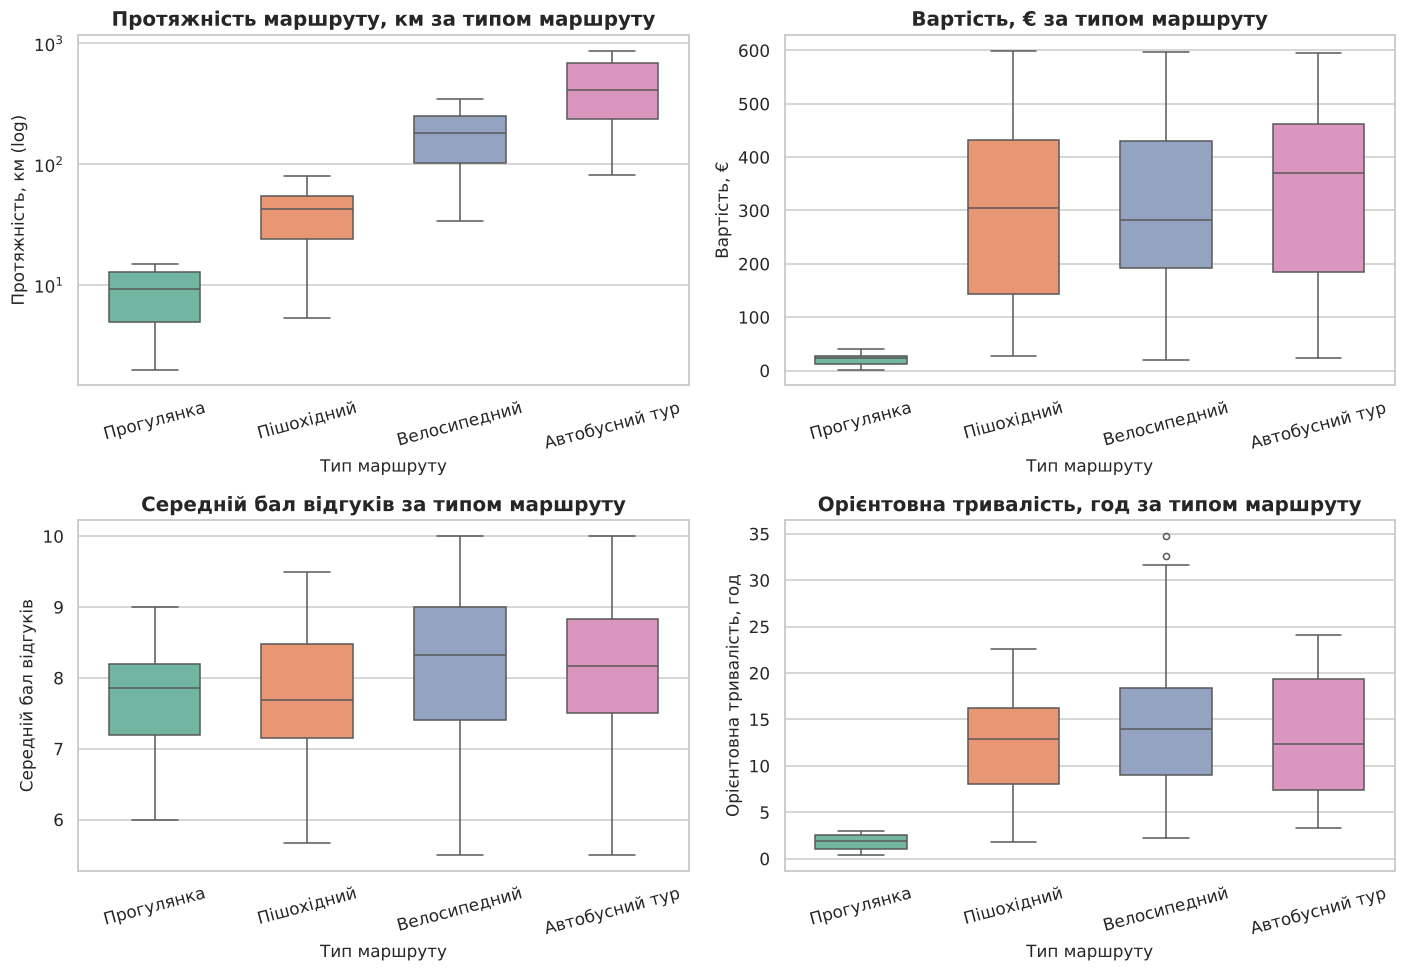

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, label) in zip(axes.ravel(), variables.items()):
    sns.boxplot(data=df, x="type_ua", y=col, hue="type_ua", order=TYPE_ORDER, palette=PALETTE, legend=False, dodge=False, width=0.6,
                flierprops={"marker": "o", "markersize": 4}, ax=ax)
    ax.set(title=label + " за типом маршруту", xlabel="Тип маршруту", ylabel=label)
    ax.tick_params(axis="x", rotation=15)
axes[0, 0].set_yscale("log")
axes[0, 0].set_ylabel("Протяжність, км (log)")
plt.tight_layout()
save("05_boxplots_by_type")
plt.show()

In [14]:
# Викиди за IQR, але в межах свого типу маршруту: порівнювати 5-км прогулянку й 800-км автотур в одній вибірці некоректно
def outliers_within_group(data, col, group="type_ua"):
    parts = []
    for name, part in data.groupby(group, observed=True):
        q1, q3 = part[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        mask = (part[col] < q1 - 1.5 * iqr) | (part[col] > q3 + 1.5 * iqr)
        parts.append(part[mask])
    return pd.concat(parts)

summary = pd.DataFrame({
    "викидів у всій вибірці": {c: int(((df[c] < df[c].quantile(.25) - 1.5 * (df[c].quantile(.75) - df[c].quantile(.25))) |
                                       (df[c] > df[c].quantile(.75) + 1.5 * (df[c].quantile(.75) - df[c].quantile(.25)))).sum())
                               for c in ["length_km", "price_eur", "duration_hours", "price_per_km"]},
    "викидів у межах типу": {c: len(outliers_within_group(df, c)) for c in ["length_km", "price_eur", "duration_hours", "price_per_km"]},
})
summary

,викидів у всій вибірці,викидів у межах типу
length_km,23,0
price_eur,0,0
duration_hours,1,2
price_per_km,24,25


In [15]:
# Найекстремальніші значення: ціна за кілометр і тривалість
cols = ["route_id", "type_ua", "name", "country", "length_km", "price_eur", "price_per_km", "duration_hours"]
print("Топ-5 за ціною за км:")
display(df.nlargest(5, "price_per_km")[cols])
print("Топ-5 за тривалістю:")
display(df.nlargest(5, "duration_hours")[cols])

Топ-5 за ціною за км:


,route_id,type_ua,name,country,length_km,price_eur,price_per_km,duration_hours
119,273,Пішохідний,Трек через Дністра (Ставангер),Норвегія,5.6,489.56,87.42,3.55
60,112,Пішохідний,Трек через Озерного краю (Львів),Україна,5.9,376.55,63.82,3.66
247,50,Пішохідний,Трек через Балтики (Гданськ),Польща,6.5,334.41,51.45,4.43
183,284,Пішохідний,Стежка Альп (Попрад),Словаччина,8.1,403.06,49.76,4.74
4,26,Пішохідний,Стежка Карпат (Пассау),Австрія,6.3,303.91,48.24,5.33


Топ-5 за тривалістю:


,route_id,type_ua,name,country,length_km,price_eur,price_per_km,duration_hours
25,34,Велосипедний,Веломаршрут Карпат (Люцерн),Швейцарія,347.4,190.96,0.55,34.74
56,212,Велосипедний,Веломаршрут Дністра (Кошице),Словаччина,326.6,282.42,0.86,32.66
191,62,Велосипедний,Велотур Карпат (Люцерн),Швейцарія,316.2,54.50,0.17,31.62
101,17,Велосипедний,Велопетля Старого міста (Краків),Польща,298.5,45.90,0.15,29.85
2,58,Велосипедний,Веломаршрут Доломітів (Відень),Австрія,293.4,248.80,0.85,29.34


**Аналіз викидів.**

| Показник | Викидів у всій вибірці | Викидів у межах типу | Висновок |
|---|---|---|---|
| `length_km` | 23 | 0 | Усі «викиди» — довгі автобусні тури (понад 477 км; для велосипедних максимум 347 км). Це наслідок змішування різних типів, а не помилка. **Не видаляємо.** |
| `price_eur` | 0 | 0 | Викидів немає, діапазон 1,9–599 €. |
| `avg_rating` | 0 | — | Усі оцінки в допустимих межах 1–10. |
| `duration_hours` | 1 | 2 | Два велосипедні маршрути (34,7 і 32,7 год): довгі (≈ 330–350 км) гірськовелосипедні тури, тривалість узгоджується з протяжністю та швидкістю 10 км/год — реальні значення. **Не видаляємо.** |
| `price_per_km` | 24 | 25 | Усі 24 викиди — пішохідні маршрути довжиною 5–35 км і вартістю 183–599 €; найекстремальніші мають 5–8 км при 300–490 €, звідси до 87 € за км. Показник є відношенням `price_eur / length_km`, тому для коротких маршрутів він завжди «вибухає». У реальних даних такі записи варто було б перевірити, але вони не суперечать допустимим межам, тож ми їх залишаємо. |

**Загалом:** жоден викид не було видалено, оскільки кожен має пояснення (різні типи маршрутів, похідний показник) і не порушує допустимих меж із ЛР 2. Це відповідає застереженню з теорії: викид не завжди є помилкою.

### 4.3. Violin Plot: форма розподілу середнього балу за типами

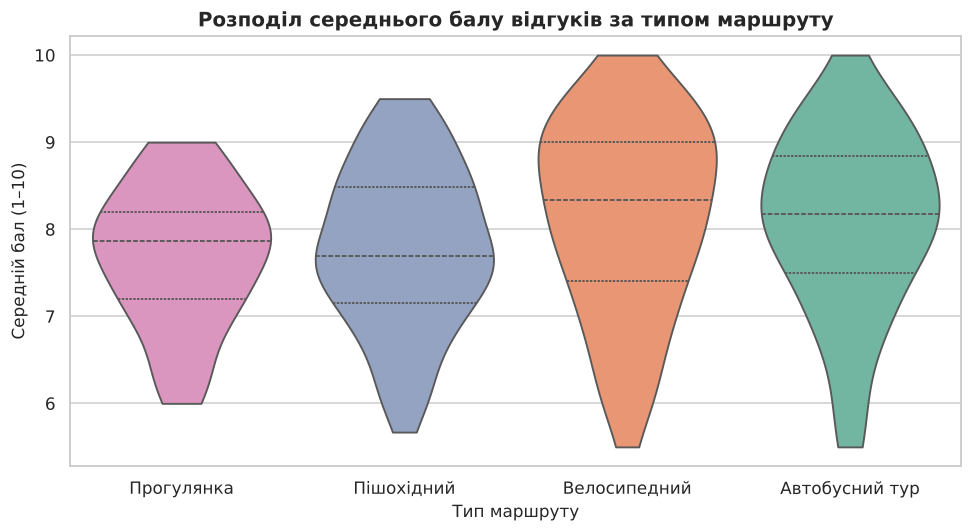

In [16]:
plt.figure(figsize=(9, 5))
sns.violinplot(data=df, x="type_ua", y="avg_rating", hue="type_ua", order=TYPE_ORDER, palette=PALETTE,
               inner="quartile", legend=False, cut=0, dodge=False)
plt.title("Розподіл середнього балу відгуків за типом маршруту")
plt.xlabel("Тип маршруту")
plt.ylabel("Середній бал (1–10)")
plt.tight_layout()
save("06_violin_rating_by_type")
plt.show()

## 5. Категоріальні дані

### 5.1. Count Plot і Bar Chart: скільки маршрутів у категоріях

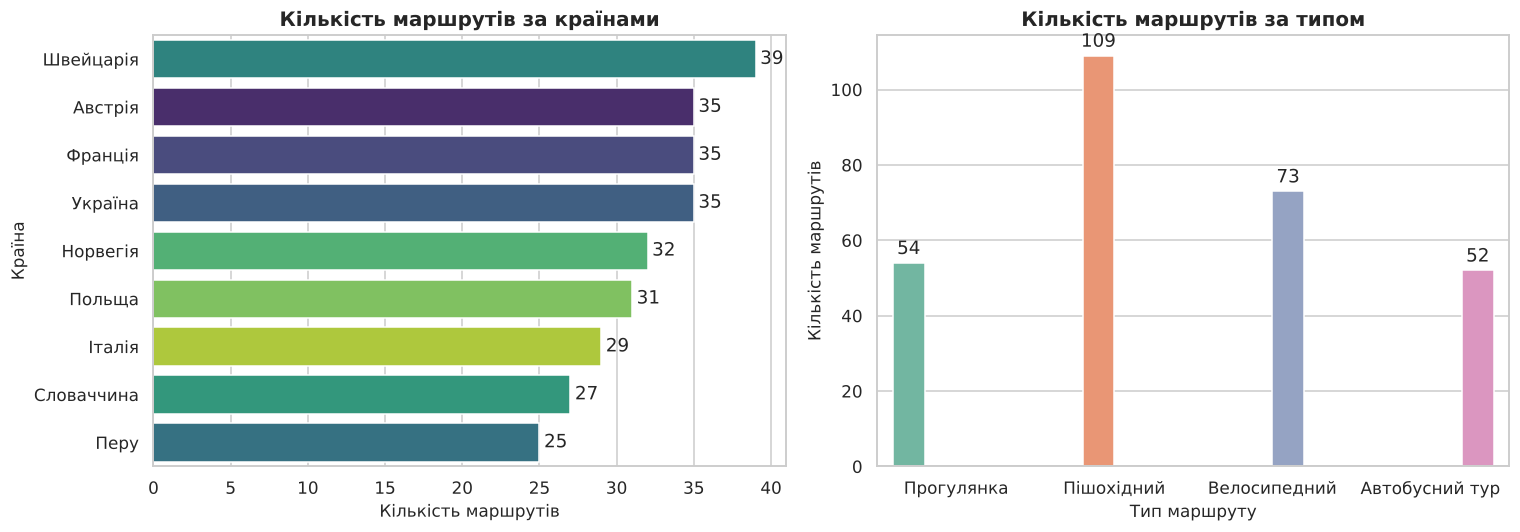

Найбільше маршрутів: Швейцарія (39); найменше: Перу (25)


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = df["country"].value_counts().index
sns.countplot(data=df, y="country", hue="country", order=order, palette="viridis", legend=False, ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, padding=3)
axes[0].set(title="Кількість маршрутів за країнами", xlabel="Кількість маршрутів", ylabel="Країна")

sns.countplot(data=df, x="type_ua", hue="type_ua", order=TYPE_ORDER, palette=PALETTE, legend=False, ax=axes[1])
for container in axes[1].containers:
    axes[1].bar_label(container, padding=3)
axes[1].set(title="Кількість маршрутів за типом", xlabel="Тип маршруту", ylabel="Кількість маршрутів")
plt.tight_layout()
save("07_counts_country_type")
plt.show()

counts = df["country"].value_counts()
print(f"Найбільше маршрутів: {counts.idxmax()} ({counts.max()}); найменше: {counts.idxmin()} ({counts.min()})")

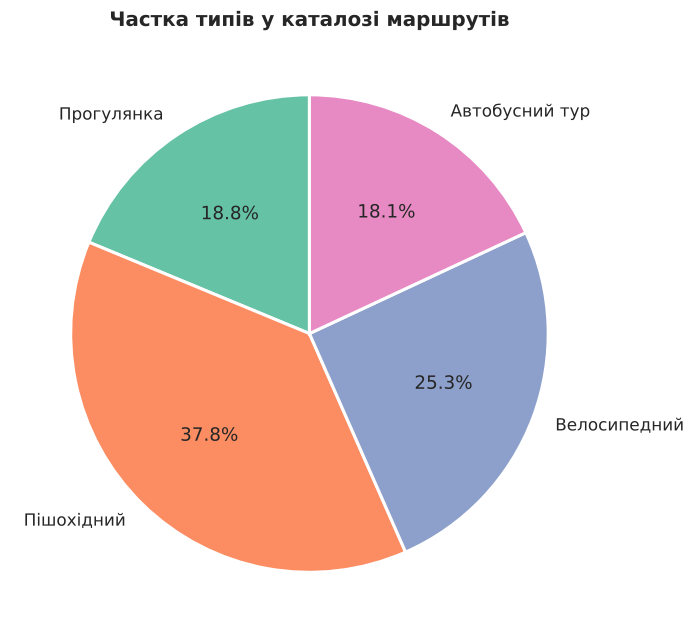

In [18]:
# Pie chart: частка типів (4 категорії — діаграма доречна)
shares = df["type_ua"].value_counts().reindex(TYPE_ORDER)
plt.figure(figsize=(6.5, 6.5))
plt.pie(shares, labels=shares.index, autopct="%1.1f%%", startangle=90, colors=[PALETTE[t] for t in shares.index],
        wedgeprops={"edgecolor": "white", "linewidth": 2})
plt.title("Частка типів у каталозі маршрутів")
plt.tight_layout()
save("08_pie_types")
plt.show()

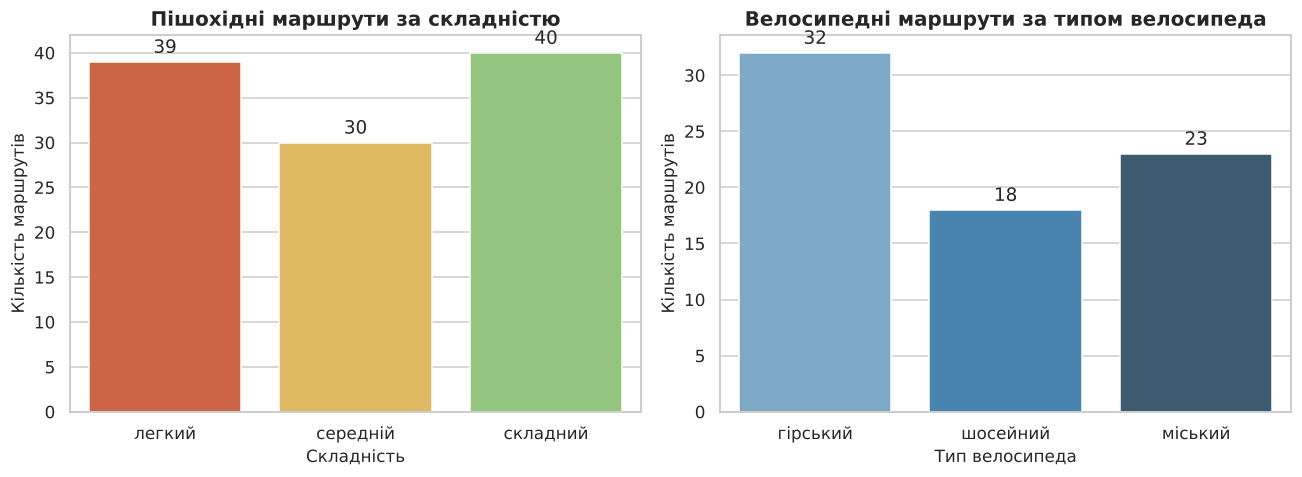

In [19]:
# Складність пішохідних маршрутів і тип велосипеда: невеликі підкаталоги
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
order_d = ["легкий", "середній", "складний"]
sns.countplot(data=df.dropna(subset=["difficulty"]), x="difficulty", hue="difficulty", order=order_d,
              palette=["#8FD175", "#F2C14E", "#E4572E"], legend=False, ax=axes[0])
axes[0].set(title="Пішохідні маршрути за складністю", xlabel="Складність", ylabel="Кількість маршрутів")
sns.countplot(data=df.dropna(subset=["bike_type"]), x="bike_type", hue="bike_type", palette="Blues_d", legend=False, ax=axes[1])
axes[1].set(title="Велосипедні маршрути за типом велосипеда", xlabel="Тип велосипеда", ylabel="Кількість маршрутів")
for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, padding=3)
plt.tight_layout()
save("09_difficulty_bike")
plt.show()

### 5.2. Порівняння числових показників між категоріями

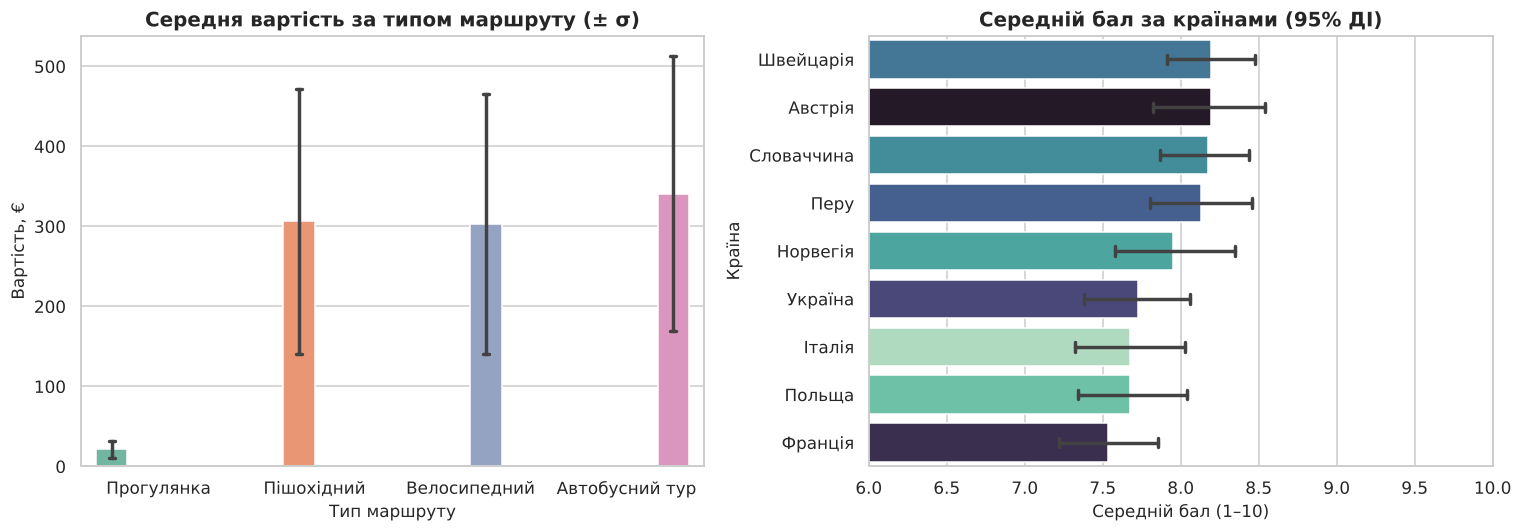

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df, x="type_ua", y="price_eur", hue="type_ua", order=TYPE_ORDER, palette=PALETTE, legend=False,
            errorbar="sd", capsize=0.15, ax=axes[0])
axes[0].set(title="Середня вартість за типом маршруту (± σ)", xlabel="Тип маршруту", ylabel="Вартість, €")

country_order = df.groupby("country")["avg_rating"].mean().sort_values(ascending=False).index
sns.barplot(data=df, y="country", x="avg_rating", hue="country", order=country_order, palette="mako", legend=False,
            errorbar=("ci", 95), capsize=0.2, ax=axes[1])
axes[1].set(title="Середній бал за країнами (95% ДІ)", xlabel="Середній бал (1–10)", ylabel="Країна", xlim=(6, 10))
plt.tight_layout()
save("10_bar_price_rating")
plt.show()

**Інтерпретація.**

- **За країнами:** найбільше маршрутів у Швейцарії (39), найменше — у Перу (25). Каталог розподілений відносно рівномірно, різкого домінування однієї країни немає.
- **За типами:** найбільше пішохідних маршрутів (109, ≈ 37,8 %), далі велосипедні (73, ≈ 25,3 %), прогулянки (54, ≈ 18,8 %) і автобусні тури (52, ≈ 18,1 %). Найменш представлений тип — автобусні тури.
- **Вартість:** прогулянки (≈ 21 €) принципово дешевші за інші типи (≈ 300–340 €); найдорожчі автобусні тури (≈ 341 €). Великі планки похибок (± σ) показують, що всередині типів ціни дуже розрізняються.
- **Середній бал за країнами:** лідирують Швейцарія (8,20) та Австрія (8,19), найнижчий бал у Франції (7,54). Довірчі інтервали сусідніх країн значною мірою перекриваються, тому статистично надійно відрізняються лише крайні значення; різниця в ≈ 0,6 бала — невелика.

## 6. Взаємозв'язок числових змінних

### 6.1. Scatter Plot із трендовими лініями

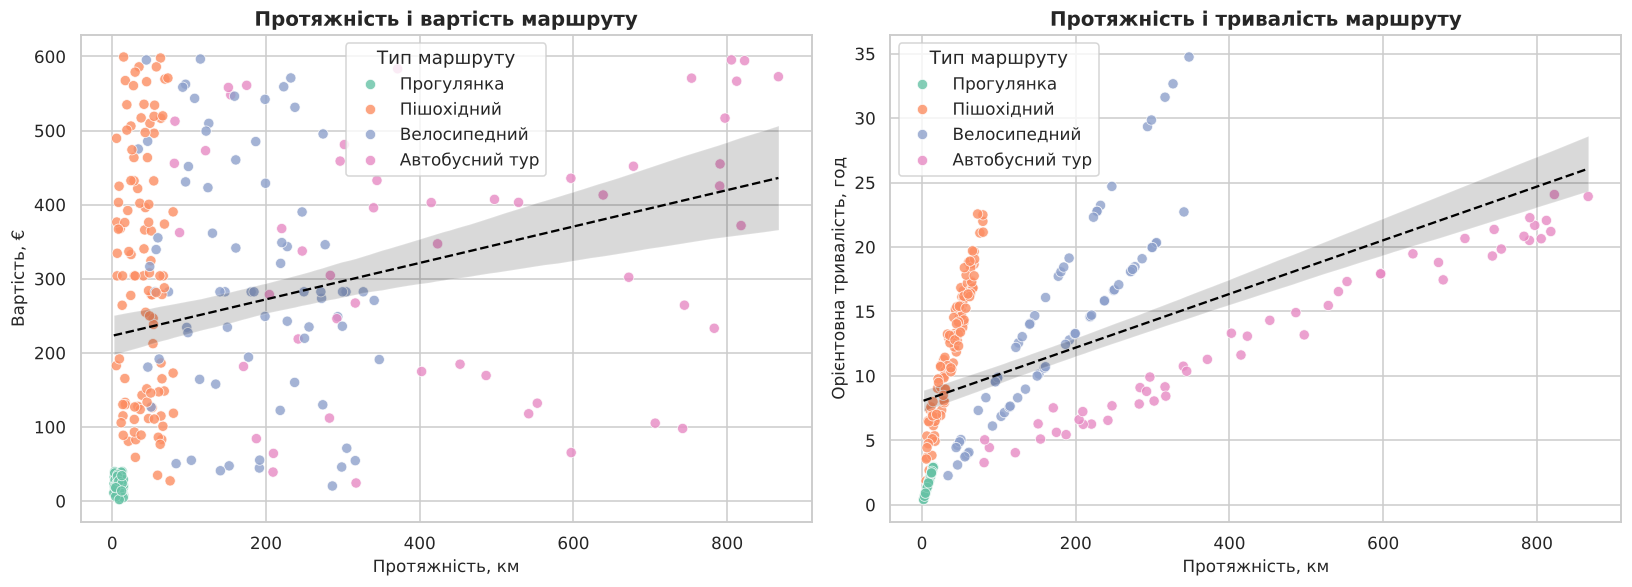

r(length_km, price_eur) = 0.25
r(length_km, duration_hours) = 0.57


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(data=df, x="length_km", y="price_eur", hue="type_ua", hue_order=TYPE_ORDER, palette=PALETTE,
                s=45, alpha=0.8, ax=axes[0])
sns.regplot(data=df, x="length_km", y="price_eur", scatter=False, color="black", line_kws={"ls": "--", "lw": 1.5}, ax=axes[0])
axes[0].set(title="Протяжність і вартість маршруту", xlabel="Протяжність, км", ylabel="Вартість, €")
axes[0].legend(title="Тип маршруту")

sns.scatterplot(data=df, x="length_km", y="duration_hours", hue="type_ua", hue_order=TYPE_ORDER, palette=PALETTE,
                s=45, alpha=0.8, ax=axes[1])
sns.regplot(data=df, x="length_km", y="duration_hours", scatter=False, color="black", line_kws={"ls": "--", "lw": 1.5}, ax=axes[1])
axes[1].set(title="Протяжність і тривалість маршруту", xlabel="Протяжність, км", ylabel="Орієнтовна тривалість, год")
axes[1].legend(title="Тип маршруту")
plt.tight_layout()
save("11_scatter_length_price_duration")
plt.show()

for x, y in [("length_km", "price_eur"), ("length_km", "duration_hours")]:
    print(f"r({x}, {y}) = {df[x].corr(df[y]):.2f}")

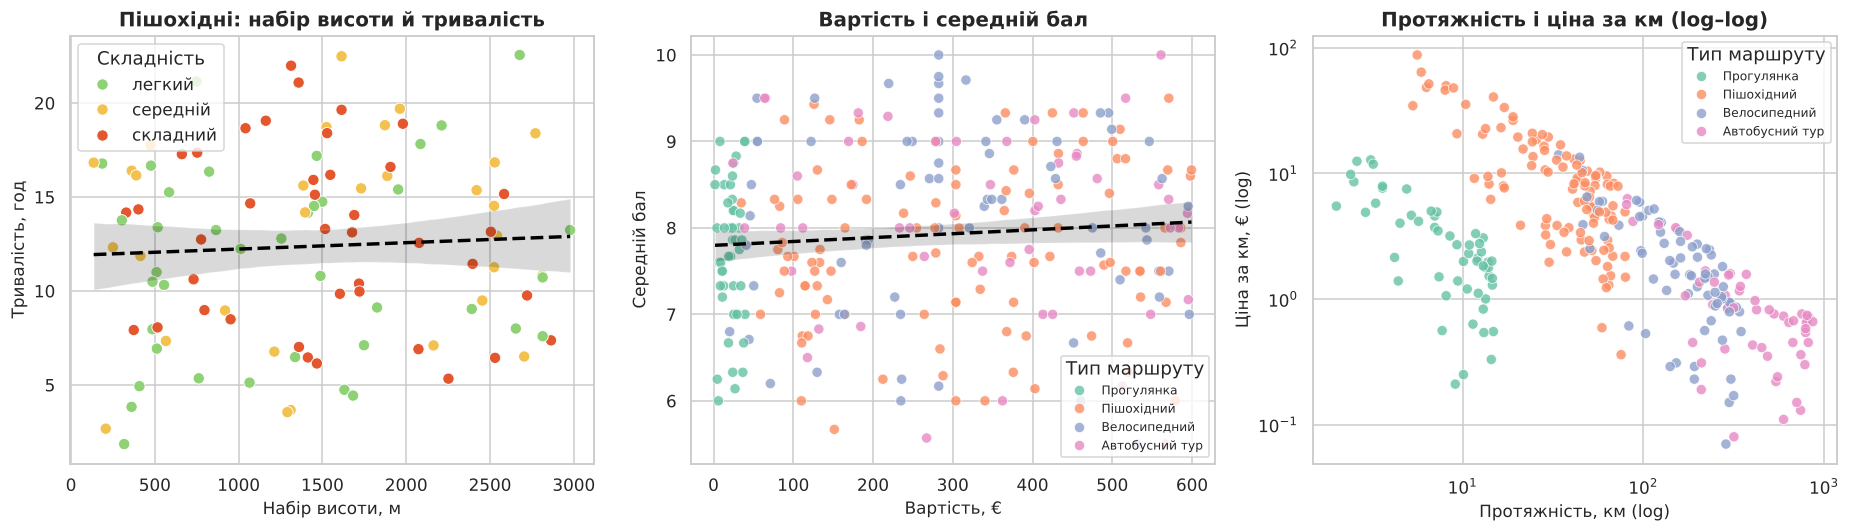

r(elevation, duration | піші) = 0.05
r(price, avg_rating) = 0.09
r(log length, log price_per_km) = -0.6


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

hike = df[df["type"] == "HikingRoute"]
sns.scatterplot(data=hike, x="elevation_gain_m", y="duration_hours", hue="difficulty",
                hue_order=["легкий", "середній", "складний"], palette=["#8FD175", "#F2C14E", "#E4572E"], s=55, ax=axes[0])
sns.regplot(data=hike, x="elevation_gain_m", y="duration_hours", scatter=False, color="black", line_kws={"ls": "--"}, ax=axes[0])
axes[0].set(title="Пішохідні: набір висоти й тривалість", xlabel="Набір висоти, м", ylabel="Тривалість, год")
axes[0].legend(title="Складність")

sns.scatterplot(data=df, x="price_eur", y="avg_rating", hue="type_ua", hue_order=TYPE_ORDER, palette=PALETTE, s=45, alpha=0.8, ax=axes[1])
sns.regplot(data=df, x="price_eur", y="avg_rating", scatter=False, color="black", line_kws={"ls": "--"}, ax=axes[1])
axes[1].set(title="Вартість і середній бал", xlabel="Вартість, €", ylabel="Середній бал")
axes[1].legend(title="Тип маршруту", fontsize=8)

sns.scatterplot(data=df, x="length_km", y="price_per_km", hue="type_ua", hue_order=TYPE_ORDER, palette=PALETTE, s=45, alpha=0.8, ax=axes[2])
axes[2].set(xscale="log", yscale="log", title="Протяжність і ціна за км (log–log)", xlabel="Протяжність, км (log)", ylabel="Ціна за км, € (log)")
axes[2].legend(title="Тип маршруту", fontsize=8)
plt.tight_layout()
save("12_scatter_more_pairs")
plt.show()

print("r(elevation, duration | піші) =", round(hike["elevation_gain_m"].corr(hike["duration_hours"]), 2))
print("r(price, avg_rating) =", round(df["price_eur"].corr(df["avg_rating"]), 2))
print("r(log length, log price_per_km) =", round(np.log(df["length_km"]).corr(np.log(df["price_per_km"])), 2))

**Інтерпретація.**

- **Протяжність і вартість:** слабкий прямий зв'язок (r ≈ 0,25). Короткі й дешеві прогулянки зібрані в лівому нижньому куті й «тягнуть» тренд угору; у решти типів вартість розкидана від 20 до 600 € незалежно від довжини. Тобто довший маршрут не обов'язково дорожчий.
- **Протяжність і тривалість:** помірний прямий зв'язок (r ≈ 0,57). Точки утворюють кілька «променів» — по одному на кожен тип, бо нахил визначається швидкістю (піші 4 км/год, велосипедні 10–15, автобус 40). Тривалість обчислена з протяжності, тому зв'язок механічний.
- **Набір висоти й тривалість (піші):** зв'язку майже немає (r ≈ 0,05): внесок підйому в тривалість (до ≈ 5 год) менший за внесок довжини, а самі змінні між собою не пов'язані.
- **Вартість і середній бал:** зв'язку немає (r ≈ 0,09) — дорожчі маршрути оцінюють не вищим балом.
- **Протяжність і ціна за км:** на log–log шкалі чітка спадна залежність (r ≈ −0,60). Це математичний ефект: вартість майже не залежить від довжини, тому ціна за км обернено пропорційна протяжності.
- **Точки поза основною групою:** це короткі пішохідні маршрути з надвисокою ціною за км (див. розділ 4.2).

## 7. Кореляційний аналіз

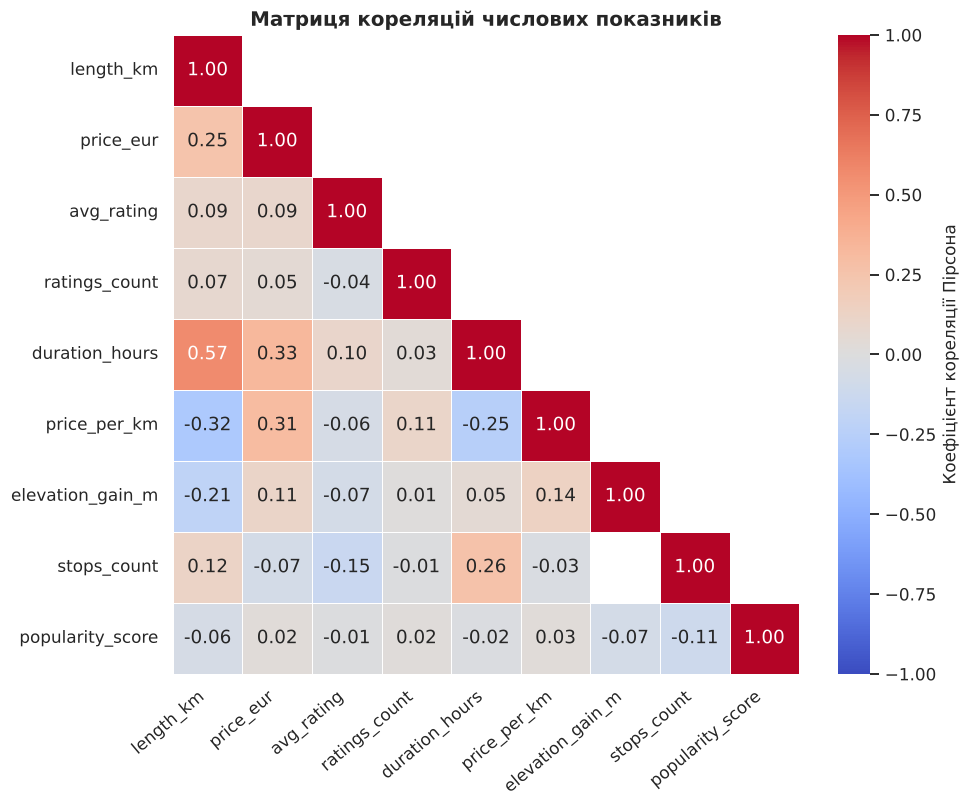

In [23]:
corr_cols = ["length_km", "price_eur", "avg_rating", "ratings_count", "duration_hours",
             "price_per_km", "elevation_gain_m", "stops_count", "popularity_score"]
corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(9, 7.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.set_style("white")
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.5, cbar_kws={"label": "Коефіцієнт кореляції Пірсона"})
plt.title("Матриця кореляцій числових показників")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
save("13_correlation_heatmap")
plt.show()
sns.set_style("whitegrid")

In [24]:
pairs = (corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool))
             .stack().rename("r").reset_index()
             .rename(columns={"level_0": "змінна 1", "level_1": "змінна 2"}))
print("Найсильніші прямі зв'язки:")
display(pairs.sort_values("r", ascending=False).head(5).round(2))
print("Найсильніші обернені зв'язки:")
display(pairs.sort_values("r").head(5).round(2))
print("Найслабші зв'язки (|r| найменший):")
display(pairs.reindex(pairs["r"].abs().sort_values().index).head(3).round(2))

Найсильніші прямі зв'язки:


,змінна 1,змінна 2,r
36,duration_hours,length_km,0.57
37,duration_hours,price_eur,0.33
46,price_per_km,price_eur,0.31
67,stops_count,duration_hours,0.26
9,price_eur,length_km,0.25


Найсильніші обернені зв'язки:


,змінна 1,змінна 2,r
45,price_per_km,length_km,-0.32
49,price_per_km,duration_hours,-0.25
54,elevation_gain_m,length_km,-0.21
65,stops_count,avg_rating,-0.15
79,popularity_score,stops_count,-0.11


Найслабші зв'язки (|r| найменший):


,змінна 1,змінна 2,r
74,popularity_score,avg_rating,-0.01
66,stops_count,ratings_count,-0.01
57,elevation_gain_m,ratings_count,0.01


**Інтерпретація.**

- **Найсильніші прямі зв'язки:** `duration_hours` — `length_km` (0,57), `duration_hours` — `price_eur` (0,33), `price_per_km` — `price_eur` (0,31), `stops_count` — `duration_hours` (0,26), `price_eur` — `length_km` (0,25).
- **Найсильніші обернені:** `price_per_km` — `length_km` (−0,32), `price_per_km` — `duration_hours` (−0,25), `elevation_gain_m` — `length_km` (−0,21), `stops_count` — `avg_rating` (−0,15).
- **Найслабші:** `popularity_score` — `avg_rating` (−0,01), `stops_count` — `ratings_count` (−0,01), `elevation_gain_m` — `ratings_count` (0,01).

**Висновки.** Сильних кореляцій (|r| > 0,7) у датасеті немає, найвище значення — 0,57. Більшість помітних зв'язків є «похідними»: тривалість обчислено з протяжності, зупинок і набору висоти, а ціна за км — з ціни та протяжності, тому їх не варто вважати відкриттям. Оцінки відгуків практично не пов'язані з жодною змінною (|r| ≤ 0,15). Змінна `popularity_score` згенерована випадково, і її кореляції близькі до нуля — це підтверджує, що метод не «вигадує» зв'язків там, де їх немає. Також потрібно пам'ятати, що коефіцієнт Пірсона вимірює лише лінійний зв'язок, не доводить причинності, а змішування різних типів маршрутів (особливо прогулянок) спотворює оцінки.

## 8. Групування та порівняння даних

In [25]:
by_type = (df.groupby("type_ua", observed=True)
             .agg(routes=("route_id", "count"), total_km=("length_km", "sum"), avg_length=("length_km", "mean"),
                  min_length=("length_km", "min"), max_length=("length_km", "max"),
                  avg_price=("price_eur", "mean"), avg_rating=("avg_rating", "mean"),
                  avg_duration=("duration_hours", "mean"), avg_price_per_km=("price_per_km", "mean"))
             .round(2))
by_type

,routes,total_km,avg_length,min_length,max_length,avg_price,avg_rating,avg_duration,avg_price_per_km
type_ua,,,,,,,,,
Прогулянка,54,483.4,8.95,2.0,14.8,21.35,7.70,1.79,3.44
Пішохідний,109,4352.3,39.93,5.3,79.6,306.53,7.79,12.38,12.51
Велосипедний,73,13064.9,178.97,33.9,347.4,302.71,8.15,14.34,2.57
Автобусний тур,52,23405.5,450.11,80.8,866.7,340.87,8.07,13.09,1.20


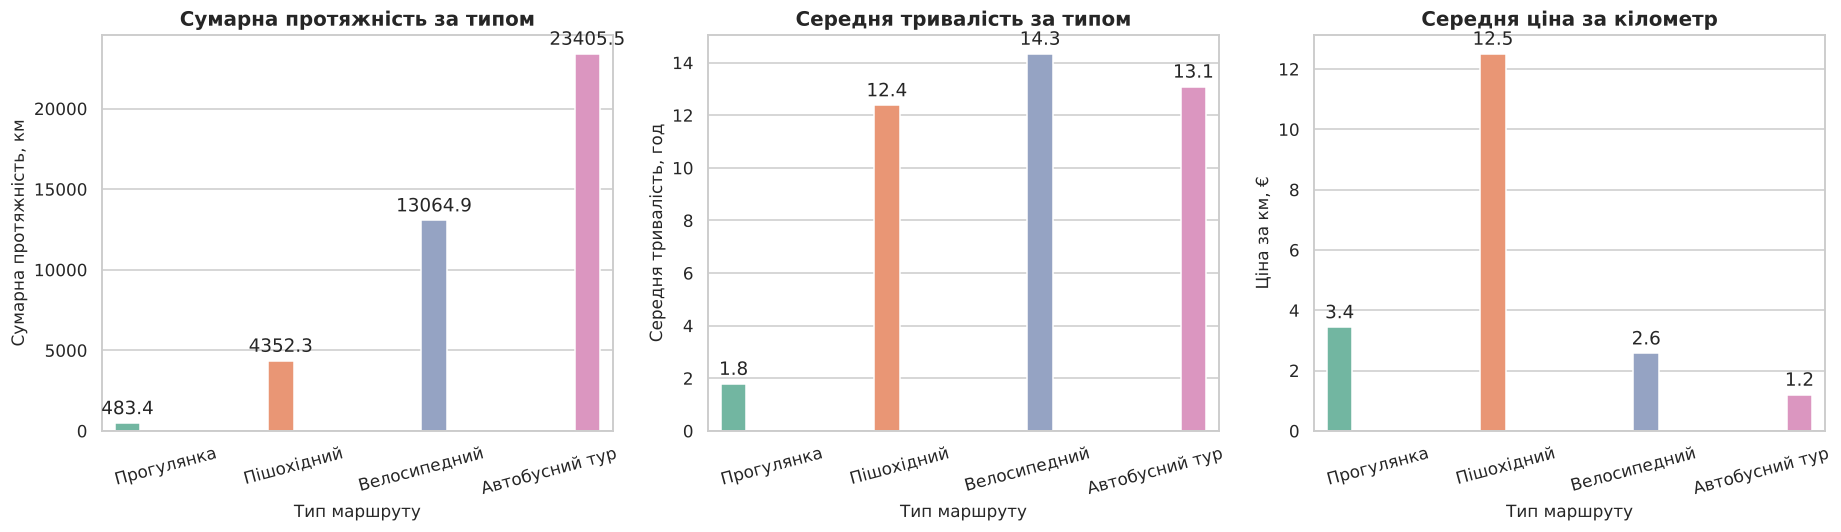

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (col, title, ylabel) in zip(axes, [
        ("total_km", "Сумарна протяжність за типом", "Сумарна протяжність, км"),
        ("avg_duration", "Середня тривалість за типом", "Середня тривалість, год"),
        ("avg_price_per_km", "Середня ціна за кілометр", "Ціна за км, €")]):
    sns.barplot(x=by_type.index, y=by_type[col], hue=by_type.index, palette=PALETTE, legend=False, ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt="%.1f", padding=3)
    ax.set(title=title, xlabel="Тип маршруту", ylabel=ylabel)
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
save("14_groupby_type_bars")
plt.show()

,routes,avg_length,avg_price,avg_rating
country,,,,
Швейцарія,39,180.36,270.28,8.20
Австрія,35,142.05,290.58,8.19
Словаччина,27,141.76,307.44,8.17
Перу,25,122.70,289.59,8.13
Норвегія,32,121.13,202.09,7.95
Україна,35,154.36,274.21,7.72
Італія,29,148.95,221.37,7.67
Польща,31,134.03,271.15,7.67
Франція,35,132.91,207.05,7.54


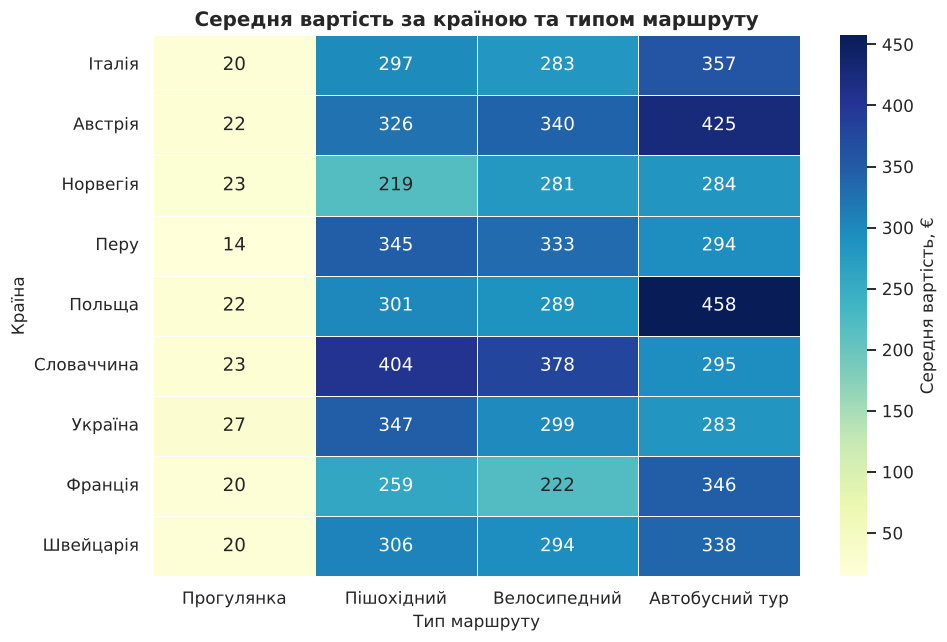

In [27]:
by_country = (df.groupby("country")
                .agg(routes=("route_id", "count"), avg_length=("length_km", "mean"),
                     avg_price=("price_eur", "mean"), avg_rating=("avg_rating", "mean"))
                .round(2).sort_values("avg_rating", ascending=False))
display(by_country)

pivot_price = df.pivot_table(index="country", columns="type_ua", values="price_eur", aggfunc="mean", observed=True)[TYPE_ORDER]
plt.figure(figsize=(9, 6))
sns.set_style("white")
sns.heatmap(pivot_price, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5, cbar_kws={"label": "Середня вартість, €"})
plt.title("Середня вартість за країною та типом маршруту")
plt.xlabel("Тип маршруту")
plt.ylabel("Країна")
plt.tight_layout()
save("15_heatmap_country_type_price")
plt.show()
sns.set_style("whitegrid")

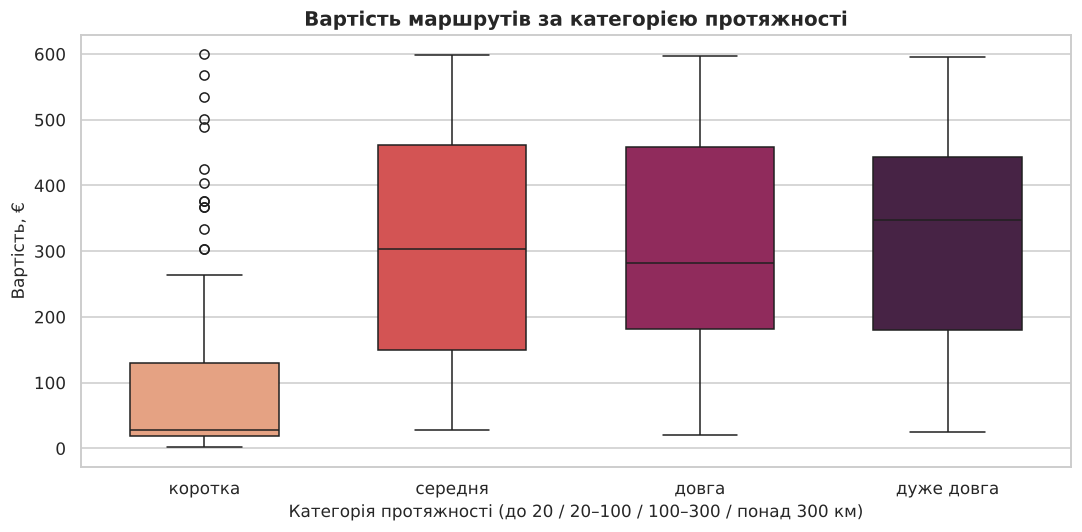

,count,mean,median
length_class,,,
коротка,78,110.4,27.2
середня,106,315.4,303.9
довга,65,302.0,282.4
дуже довга,39,326.0,347.2


In [28]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="length_class", y="price_eur", hue="length_class", palette="rocket_r", legend=False, dodge=False, width=0.6)
plt.title("Вартість маршрутів за категорією протяжності")
plt.xlabel("Категорія протяжності (до 20 / 20–100 / 100–300 / понад 300 км)")
plt.ylabel("Вартість, €")
plt.tight_layout()
save("16_box_price_by_length_class")
plt.show()
df.groupby("length_class", observed=True)["price_eur"].agg(["count", "mean", "median"]).round(1)

**Порівняння груп.**

- **За типом:** автобусні тури дають найбільшу сумарну протяжність (≈ 23 405 км), далі велосипедні (≈ 13 065 км), пішохідні (≈ 4 352 км) і прогулянки (≈ 483 км). Середня тривалість: прогулянки ≈ 1,8 год, а пішохідні, велосипедні та автобусні — 12,4–14,3 год.
- **Ціна за км:** найвища у пішохідних маршрутів (≈ 12,5 €), найнижча у автобусних турів (≈ 1,2 €); велосипедні (≈ 2,6 €) і прогулянки (≈ 3,4 €) посередині. Високе середнє пішохідних зумовлене короткими маршрутами з високою ціною (див. викиди).
- **Середній бал за типом:** різниця невелика — від 7,70 (прогулянки) до 8,15 (велосипедні).
- **За країнами:** Швейцарія й Австрія мають найвищий середній бал (≈ 8,2), Франція — найнижчий (7,54); найвища середня вартість у Словаччині (≈ 307 €), найнижча у Норвегії (≈ 202 €). Теплова карта показує, що різниця в цінах між країнами всередині одного типу не має чіткої закономірності — прогулянки скрізь дешеві, а інші типи коливаються приблизно від 220 до 460 € залежно від країни.
- **За категорією протяжності:** вартість зростає лише при переході від «короткої» (середня 110 €) до «середньої» (315 €), далі тримається на рівні ≈ 300–330 €. Це пояснюється тим, що всі дешеві прогулянки потрапляють у категорію «коротка», а не впливом довжини як такої. Довші маршрути не є пропорційно дорожчими.

## 9. Часові дані: Line Plot

Стовпець `date_added` містить дату додавання маршруту до каталогу (2023–2026). Останній неповний місяць (4 дні січня 2026) виключаємо з аналізу, щоб не створювати штучного «спаду».

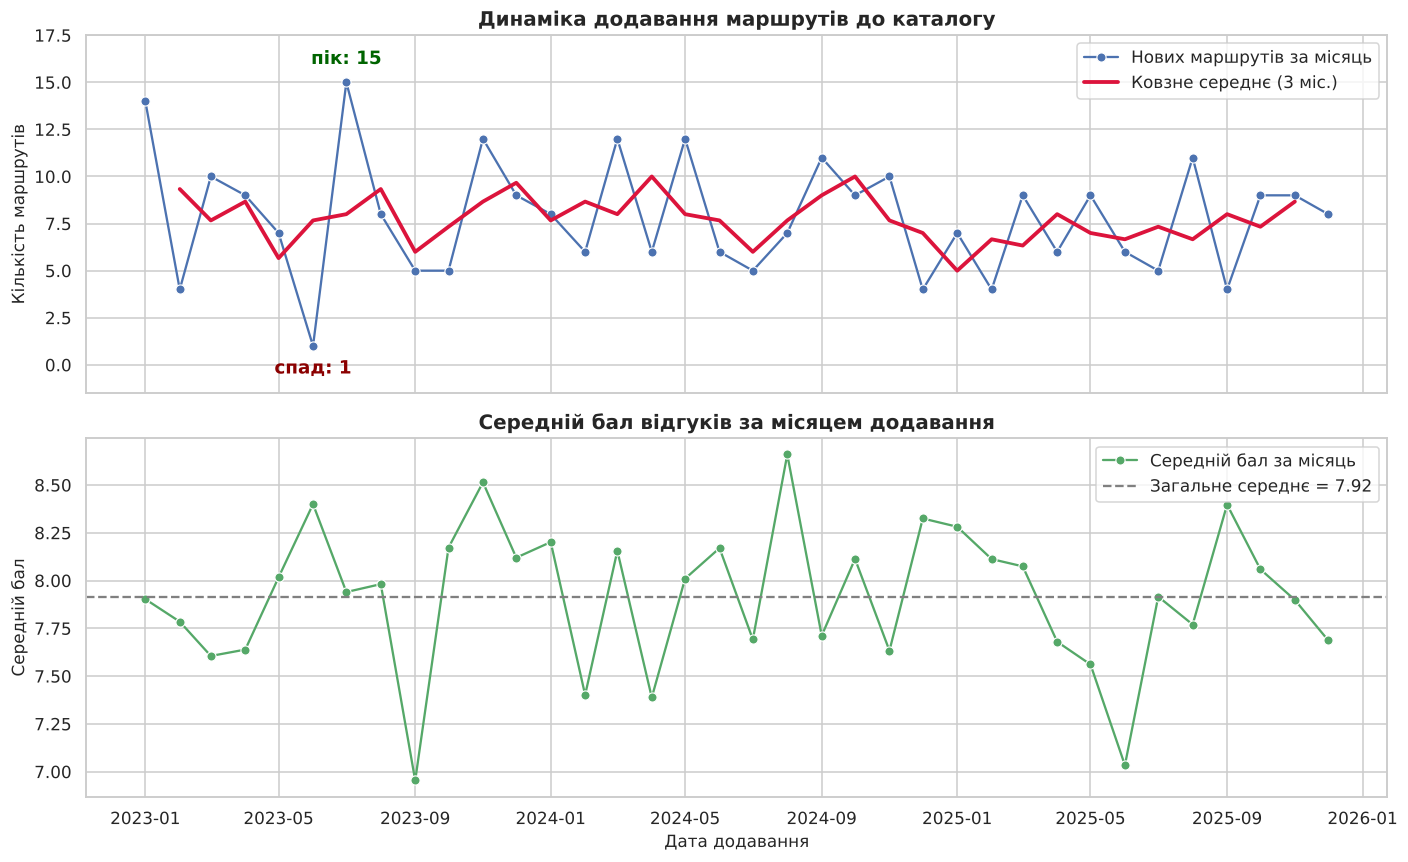

Пік: 2023-07 15 | мінімум: 2023-06 1
Середнє за місяць: 7.8


In [29]:
dated = df.dropna(subset=["date_added"])
dated = dated[dated["date_added"] < "2026-01-01"]

monthly = dated.set_index("date_added").resample("MS").agg(routes=("route_id", "count"), avg_rating=("avg_rating", "mean"))
monthly["routes_ma3"] = monthly["routes"].rolling(3, center=True).mean()

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
sns.lineplot(x=monthly.index, y=monthly["routes"], marker="o", color="#4C72B0", label="Нових маршрутів за місяць", ax=axes[0])
sns.lineplot(x=monthly.index, y=monthly["routes_ma3"], color="crimson", lw=2.5, label="Ковзне середнє (3 міс.)", ax=axes[0])
peak, low = monthly["routes"].idxmax(), monthly["routes"].idxmin()
axes[0].annotate(f"пік: {monthly['routes'].max()}", (peak, monthly["routes"].max()), xytext=(0, 12),
                 textcoords="offset points", ha="center", color="darkgreen", fontweight="bold")
axes[0].annotate(f"спад: {monthly['routes'].min()}", (low, monthly["routes"].min()), xytext=(0, -18),
                 textcoords="offset points", ha="center", color="darkred", fontweight="bold")
axes[0].set(title="Динаміка додавання маршрутів до каталогу", ylabel="Кількість маршрутів")
axes[0].margins(y=0.18)

sns.lineplot(x=monthly.index, y=monthly["avg_rating"], marker="o", color="#55A868", label="Середній бал за місяць", ax=axes[1])
axes[1].axhline(df["avg_rating"].mean(), color="gray", ls="--", label=f"Загальне середнє = {df['avg_rating'].mean():.2f}")
axes[1].set(title="Середній бал відгуків за місяцем додавання", xlabel="Дата додавання", ylabel="Середній бал")
axes[1].legend()
plt.tight_layout()
save("17_line_time")
plt.show()

print("Пік:", peak.strftime("%Y-%m"), monthly["routes"].max(), "| мінімум:", low.strftime("%Y-%m"), monthly["routes"].min())
print("Середнє за місяць:", round(monthly["routes"].mean(), 1))

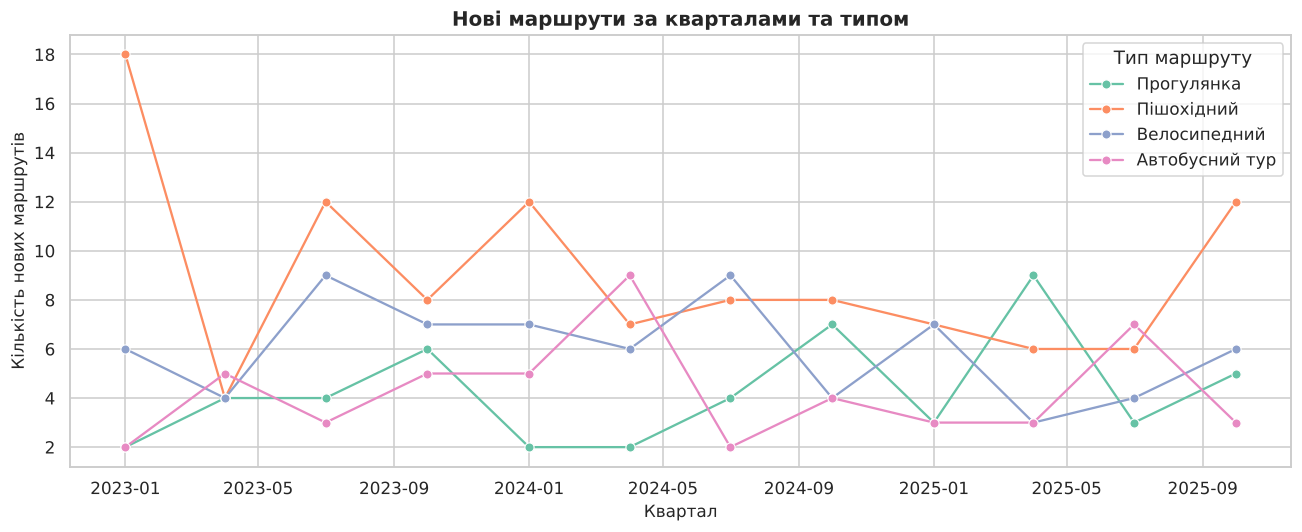

In [30]:
# Річна й квартальна динаміка за типом маршруту
quarterly = (dated.assign(quarter=dated["date_added"].dt.to_period("Q").dt.to_timestamp())
                  .groupby(["quarter", "type_ua"], observed=True).size().reset_index(name="routes"))
plt.figure(figsize=(12, 5))
sns.lineplot(data=quarterly, x="quarter", y="routes", hue="type_ua", hue_order=TYPE_ORDER, palette=PALETTE, marker="o")
plt.title("Нові маршрути за кварталами та типом")
plt.xlabel("Квартал")
plt.ylabel("Кількість нових маршрутів")
plt.legend(title="Тип маршруту")
plt.tight_layout()
save("18_line_quarter_type")
plt.show()

**Інтерпретація.** Протягом 2023–2025 років до каталогу додавалося в середньому ≈ 7,8 маршруту на місяць.

- **Пік і спад:** найбільше нових маршрутів — у липні 2023 (15), найменше — у червні 2023 (лише 1). Різкий провал і наступний пік поспіль виглядають як аномальний період: ймовірно, це випадковий розкид (дати в датасеті згенеровані).
- **Тенденція:** за роками кількість нових маршрутів трохи спадає (2023 — 99, 2024 — 96, 2025 — 87), середня кількість нових маршрутів на місяць: 8,3 → 8,0 → 7,3. Стійкої сезонності не видно: піки та спади в різних роках припадають на різні місяці.
- **Середній бал за місяцями** коливається приблизно від 6,95 (вер. 2023) до 8,66 (серп. 2024) навколо загального середнього 7,92 без тренду. Крайні значення припадають на місяці з малою кількістю маршрутів (5–7), тож це переважно шум малої вибірки, а не реальна зміна якості.
- **За типами** квартальні лінії сильно «пилкоподібні» через малі кількості (по кілька маршрутів на тип), тож робити висновки про окремі типи за часом не можна.

## 10. Pair Plot: загальний огляд зв'язків

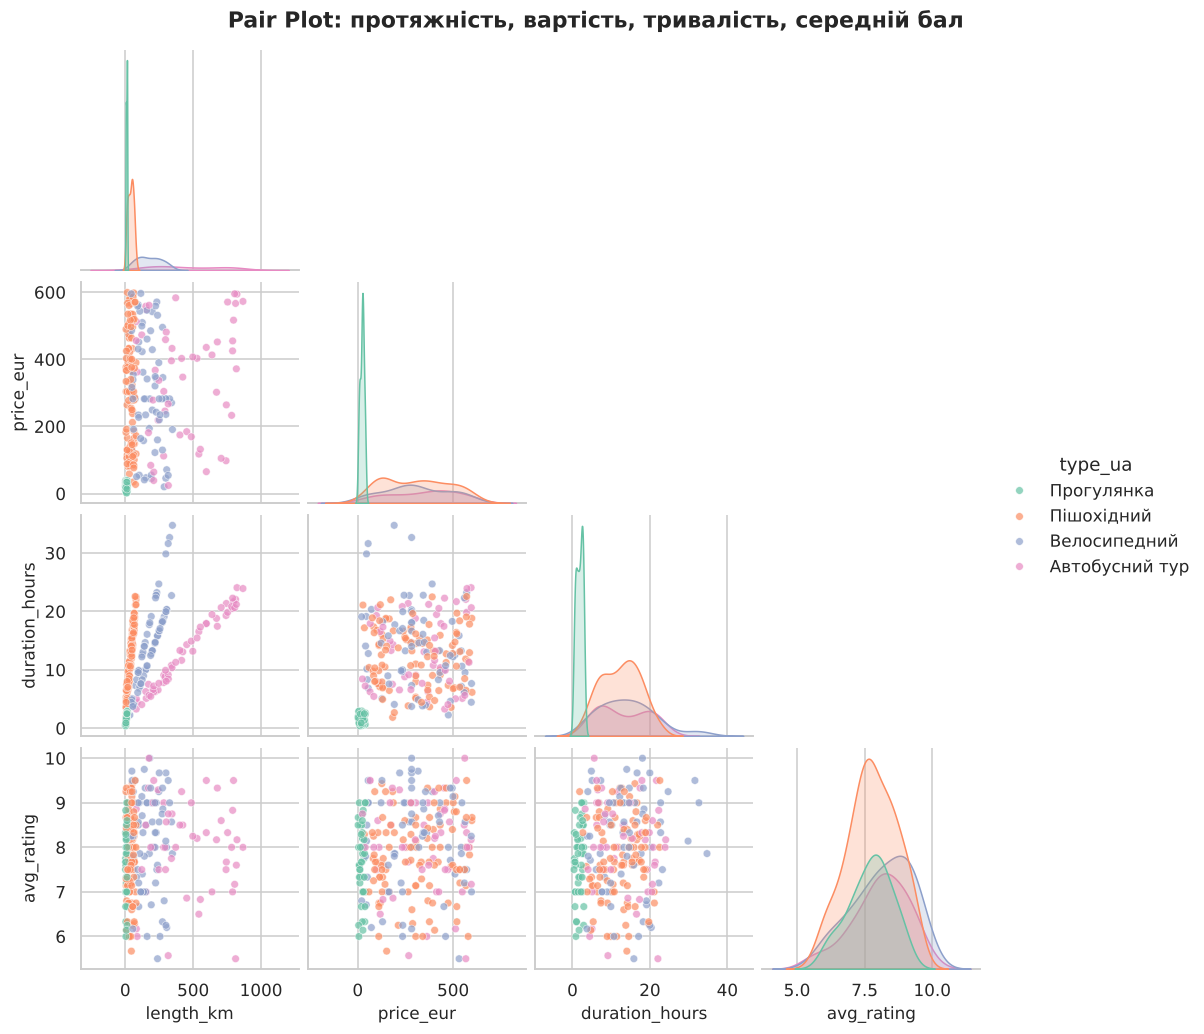

In [31]:
pair = sns.pairplot(df[["length_km", "price_eur", "duration_hours", "avg_rating", "type_ua"]].dropna(),
                    hue="type_ua", hue_order=TYPE_ORDER, palette=PALETTE, corner=True, diag_kind="kde",
                    plot_kws={"s": 25, "alpha": 0.7}, height=2.3)
pair.figure.suptitle("Pair Plot: протяжність, вартість, тривалість, середній бал", y=1.02, fontweight="bold")
pair.savefig(FIG_DIR / "19_pairplot.png", dpi=130)
plt.show()

## 11. Збережені графіки

In [32]:
for path in sorted(FIG_DIR.glob("*.png")):
    print(f"{path.name:<45} {path.stat().st_size / 1024:6.0f} КБ")
print("\nУсього графіків:", len(list(FIG_DIR.glob("*.png"))), "| папка:", FIG_DIR.resolve())

01_histograms.png                                197 КБ
02_length_linear_vs_log.png                       80 КБ
03_kde_by_type.png                               161 КБ
04_boxplots_numeric.png                           69 КБ
05_boxplots_by_type.png                          157 КБ
06_violin_rating_by_type.png                     100 КБ
07_counts_country_type.png                        84 КБ
08_pie_types.png                                  60 КБ
09_difficulty_bike.png                            63 КБ
10_bar_price_rating.png                           82 КБ
11_scatter_length_price_duration.png             256 КБ
12_scatter_more_pairs.png                        322 КБ
13_correlation_heatmap.png                       157 КБ
14_groupby_type_bars.png                         120 КБ
15_heatmap_country_type_price.png                112 КБ
16_box_price_by_length_class.png                  52 КБ
17_line_time.png                                 246 КБ
18_line_quarter_type.png                        

## 12. Загальні висновки


**Основні закономірності.**

1. Каталог складається з чотирьох чітко відокремлених за масштабом типів маршрутів. Протяжність — головний фактор, що розрізняє типи: медіани ≈ 9, 42, 181 і 409 км. Розподіл протяжності сильно скошений праворуч (skewness ≈ 2,07), тому для нього доцільніше використовувати медіану (56,5 км), а не середнє (143,4 км).
2. Вартість майже рівномірно розподілена в діапазоні 0–600 €. Єдина чітка відмінність — прогулянки (≈ 21 €) значно дешевші за решту типів (≈ 300–340 €). Довші маршрути не є пропорційно дорожчими.
3. Середній бал розподілений майже симетрично навколо 8 (діапазон 5,5–10) і слабо залежить від типу (7,7–8,15), країни (7,54–8,20) та ціни.

**Відмінності між категоріями.** Автобусні тури — найдовші (сумарно ≈ 23 405 км) і найдешевші за кілометр (≈ 1,2 €); пішохідні — найдорожчі за кілометр (≈ 12,5 €) через короткі маршрути; прогулянки — найкоротші, найшвидші й найдешевші. Найбільше маршрутів у Швейцарії (39), найменше — у Перу (25); найпоширеніший тип — пішохідний (≈ 38 %).

**Взаємозв'язки.** Сильних кореляцій немає (максимум r = 0,57 між протяжністю й тривалістю). Помітні зв'язки здебільшого механічні: тривалість і ціна за км обчислені з інших стовпців. Рейтинг не залежить ані від ціни, ані від довжини, ані від складності. Випадковий `popularity_score` має кореляції ≈ 0 з усім, як і очікувалось.

**Аномалії та викиди.** Знайдено 23 викиди за протяжністю (автобусні тури понад 477 км), 2 за тривалістю (довгі гірськовелосипедні маршрути) та 24 за ціною за км (усі — пішохідні маршрути довжиною 5–35 км). Жоден не видалено: усі мають пояснення в структурі даних і не виходять за допустимі межі з ЛР 2. Єдині записи, які в реальному датасеті варто було б перевірити вручну, — пішохідні маршрути на 5–8 км вартістю 300–490 € (до 87 € за км).

**Часова динаміка.** Додавання маршрутів помірно спадає (99 → 96 → 87 за роками), стійкої сезонності немає; різкий провал у червні 2023 (1 маршрут) — аномальний період. Коливання середнього балу за місяцями пояснюються малими вибірками.

**Обмеження.** Датасет згенерований автоматично, тому слабкі кореляції та відсутність сезонності є властивістю даних, а не ознакою реальних закономірностей туристичного ринку. На реальних даних ті самі методи слід застосовувати з додатковою перевіркою статистичної значущості.